# Grenzen des Wissens

Wie viel lässt sich über ein System überhaupt herausfinden, bevor die Natur, die Statistik oder die Rechenzeit „Stopp“ sagt? Das Notebook geht drei Arten von Grenzen an Beispielen nach: der physikalischen Grenze einer Messung beim Quantum Imaging von Doppelsternen und Exoplaneten (Fisher-Information, SPADE, mit echten Abständen aller bekannten Exoplaneten aus dem NASA Exoplanet Archive), der Heisenberg-Grenze von Quantensensoren mit Rauschen, der Rechengrenze beim Lernen verrauschter Paritäten und der statistischen Grenze bei der Evaluation von KI-Agenten. Der Code steht in [`code/`](https://github.com/deltorobarba/science/tree/main/code) (`imaging.py` für Quantum Imaging und den Planetenkatalog, `limits.py` für Metrologie, Rechengrenze und Evaluation); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Jede Messung stößt an drei Grenzen, und jede wird in einem anderen Gebiet besonders deutlich:

- **Schritte 1 bis 4, Quantum Imaging (Astrophysik und Quantenoptik):** die physikalische Grenze. Wie viel ein Photon über den Abstand zweier Sterne verrät, sagt die Quanten-Fisher-Information. Eine Kamera holt bei kleinem Abstand fast nichts davon heraus (Rayleighs Fluch), ein Sortierer nach Moden (SPADE) alles. Weil fast alle bekannten Exoplaneten unter der Beugungsgrenze liegen, entscheidet das über Millionen Photonen.
- **Schritt 5, Quantenmetrologie:** Verschränkung verschiebt die Grenze von 1/√N auf 1/N (Heisenberg-Grenze), aber Rauschen nimmt den Gewinn wieder weg.
- **Schritt 6, Informatik:** die Rechengrenze. Bei verrauschten Paritäten steckt die Antwort nach wenigen Beispielen in den Daten, wie Shannon und Fano zeigen, aber sie herauszuholen kostet exponentielle Zeit.
- **Schritt 7, KI-Evaluation:** die statistische Grenze im Alltag. Wie viele Testaufgaben braucht man, um zwei Agenten zu unterscheiden? Dieselbe Fisher-Information wie bei der Münze in der Einführung.

Die gemeinsame Lehre: Eine Grenze sagt erst dann etwas über die Natur, wenn man das beste Verfahren kennt; sonst ist sie nur die Grenze des Instruments.

**Einführung: drei Arten von Grenzen**

Ein kleines Beispiel zuerst. Eine Münze zeigt Kopf mit einer unbekannten Wahrscheinlichkeit $p$. Ein Wurf liefert die Fisher-Information $I(p) = 1/(p(1-p))$; sie misst, wie stark sich die Wahrscheinlichkeit des Ergebnisses ändert, wenn sich $p$ ändert. Nach $N$ Würfen kann kein unverzerrter Schätzer genauer sein als die Cramér-Rao-Schranke

$$\mathrm{Var}(\hat p) \ge \frac{1}{N\,I(p)} = \frac{p(1-p)}{N}.$$

Bei $p = 0.5$ und 100 Würfen sind das ±0.05; für ±0.005 braucht man 10 000 Würfe. Der Fehler schrumpft wie $1/\sqrt N$: Mehr Daten helfen langsam, aber sicher. Hinter jeder Messaufgabe stehen drei Fragen nach Grenzen:

1. **Physikalisch: Was verrät eine einzelne Messung?** Bei Quantensystemen kann man wählen, was man misst. Die Quanten-Fisher-Information $F_Q$ ist die Fisher-Information der besten aller Messungen (Braunstein und Caves 1994), und die Quanten-Cramér-Rao-Schranke $\Delta\theta \ge 1/\sqrt{N F_Q}$ gilt für jedes Messgerät. Verwandte Grenzen: $n$ Qubits übertragen höchstens $n$ Bit klassische Information (Holevo-Schranke), und zwei Quantenzustände lassen sich mit einer Messung nur bis zur Helstrom-Grenze unterscheiden.
2. **Statistisch: Wie viele Messungen braucht man?** Jede Messung trägt höchstens so viele Bit, wie ihre Kanalkapazität erlaubt (Shannon), und mit zu wenigen Daten ist jede Schätzung unsicher (Fano-Ungleichung). Diese Grenzen gelten für jedes Verfahren, gleich wie viel Rechenzeit es hat, und sie lassen sich beweisen.
3. **Rechnerisch: Wie lange dauert es, die Information herauszuholen?** Auch wenn die Daten die Antwort enthalten, kann jedes bekannte Verfahren exponentiell lange brauchen. Solche Grenzen lassen sich meist nicht beweisen; sie beruhen auf Annahmen, etwa dass verrauschte Paritäten schwer zu lernen sind, und darauf baut die Kryptographie.

| Grenze (Schritt) | System | Was verglichen wird | Ergebnis im Lauf |
|---|---|---|---|
| Physikalisch (1 bis 4) | zwei Sterne, Stern und Planet hinter einem Teleskop | Kamera gegen Quantengrenze | bei 0.1σ Abstand 8 Millionen gegen 40 000 Photonen für 10 % Genauigkeit |
| Physikalisch (5) | N Qubits als Sensor | Heisenberg-Grenze gegen Standardgrenze | mit Dephasierung kein Vorteil mehr |
| Rechnerisch (6) | Geheimnis aus n Bit, verrauschte Paritäten | Shannon und Fano gegen Suchzeit | n = 16: rund 30 Beispiele genügen, die Suche wächst wie 2^(1.1 n) |
| Statistisch (7) | zwei KI-Agenten | Binomialstatistik | 1251 Aufgaben je Agent für 70 % gegen 75 % |

In [1]:
import sys
import urllib.request
from pathlib import Path

CODE = Path.cwd() / "code"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir()
    for f in ["imaging.py", "limits.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner "code" direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import imaging, limits
DATA = Path.cwd() / "data" / "limits_of_knowledge"     # Cache für den Planetenkatalog

**1. Rayleighs Fluch: was eine Kamera über zwei nahe Sterne erfährt**

Zwei gleich helle Sterne im Abstand $\theta$ werden durch ein Teleskop abgebildet; die Beugung macht aus jedem Punkt ein Scheibchen, hier ein Gauß der Breite $\sigma$. Eine Kamera zählt die Photonen nach ihrem Ort. Wie viel Information trägt ein Photon dann über $\theta$ (`imaging.plot_rayleigh`)? Verglichen wird die Fisher-Information der Kamera mit der Quanten-Fisher-Information, der Grenze für jedes denkbare Messgerät; sie ist $1/(4\sigma^2)$, bei jedem Abstand (Tsang, Nair und Lu 2016).

**Begriffe**
- **Beugungsgrenze:** Ein Teleskop mit Durchmesser $D$ trennt Punkte bis etwa $\lambda/D$. Das Rayleigh-Kriterium nennt zwei Sterne getrennt, wenn ihr Abstand größer ist als das Scheibchen.
- **σ:** die Breite der Punktbildfunktion, rund 0.4 λ/D; bei 1.6 µm und 8 m Spiegel etwa 17 Millibogensekunden.
- **Fisher-Information pro Photon:** wie empfindlich die Verteilung eines Photons auf eine kleine Änderung von $\theta$ reagiert. Mit $N$ Photonen ist der Fehler mindestens $1/\sqrt{N I}$.

Links verschmelzen die beiden Sterne unter etwa 1σ zu einem einzigen Fleck. Rechts fällt die Fisher-Information der Kamera bei kleinem Abstand wie θ²/8 gegen null, die Quantengrenze bleibt bei 1/4: Das ist Rayleighs Fluch. Die Ausgabe übersetzt das in Photonen. Für 10 % Genauigkeit bei θ = 0.1σ braucht die Kamera 8 Millionen Photonen, ein Messgerät an der Quantengrenze 40 000, also 200-mal weniger; bei θ = 1σ ist der Unterschied nur noch das 2.9-Fache (1 165 gegen 400). Die Information steckt also im Licht, aber die Kamera wirft sie weg, sobald sie den Ort jedes Photons misst.

θ = 0.1σ: Fisher-Information pro Photon, Kamera 0.0012 (Näherung θ²/8 = 0.0013), Quantengrenze 0.25 [1/σ²]; für 10 % Genauigkeit braucht die Kamera 8 039 934 Photonen, die Quantengrenze 40 000
θ = 0.5σ: Fisher-Information pro Photon, Kamera 0.0279 (Näherung θ²/8 = 0.0312), Quantengrenze 0.25 [1/σ²]; für 10 % Genauigkeit braucht die Kamera 14 346 Photonen, die Quantengrenze 1 600
θ = 1.0σ: Fisher-Information pro Photon, Kamera 0.0858 (Näherung θ²/8 = 0.1250), Quantengrenze 0.25 [1/σ²]; für 10 % Genauigkeit braucht die Kamera 1 165 Photonen, die Quantengrenze 400


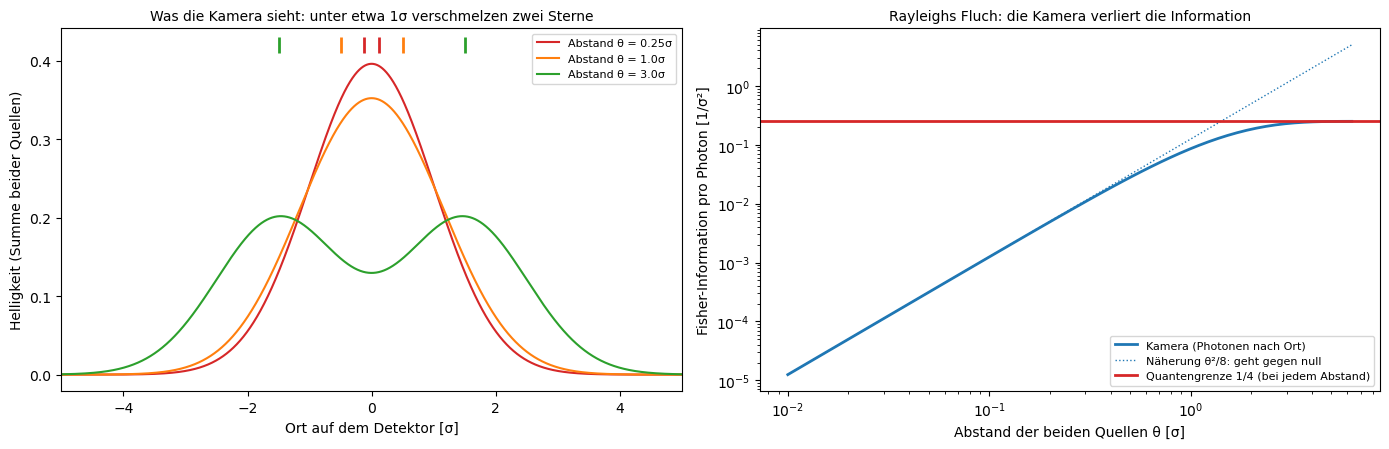

In [2]:
THETAS = (0.25, 1.0, 3.0)              # Abstände für das linke Bild [σ]
imaging.plot_rayleigh(THETAS)

**2. SPADE: Licht nach Moden sortieren statt nach Ort**

Statt den Ort jedes Photons zu messen, kann man das Licht nach seiner Form sortieren: Ein Modensortierer (Spatial-Mode Demultiplexing, SPADE) lenkt jedes Photon in einen eigenen Ausgang je Hermite-Gauß-Mode. Liegen beide Sterne auf der Achse, landet alles Licht in Mode 0; jeder Abstand schiebt den Anteil $\theta^2/16$ in Mode 1 und höher. Dieser Anteil ist das Signal, und er steht nicht neben einem großen Untergrund wie bei der Kamera. Simuliert wird, wie genau beide Verfahren den Abstand $\theta = 0.2\sigma$ aus je 10 000 Photonen schätzen, 300-mal wiederholt (`imaging.plot_estimates`).

**Begriffe**
- **Hermite-Gauß-Moden:** die Schwingungsformen eines Lichtstrahls, wie die Obertöne einer Saite; Mode 0 ist der Gauß selbst, Mode 1 hat in der Mitte einen Knoten.
- **Maximum-Likelihood:** der Abstand, unter dem die gemessenen Photonen am wahrscheinlichsten sind. Bei SPADE ist das einfach $\hat\theta = 4\sqrt{\bar q}$ mit der mittleren Modenzahl $\bar q$.
- **Unverzerrt:** Ein Schätzer, der im Mittel den wahren Wert trifft; nur für solche gilt die Cramér-Rao-Schranke.

SPADE trifft den Abstand mit einem mittleren Fehler von 0.020σ, genau auf der Quanten-Cramér-Rao-Schranke (0.020σ). Die Kamera liegt bei 0.128σ, sechsmal schlechter, und 23 % ihrer Schätzungen landen bei θ̂ = 0: Für sie sind die beiden Sterne oft nicht von einem einzigen zu unterscheiden. Ihr Fehler liegt sogar etwas unter ihrer Schranke (0.143σ), weil die vielen Nullen die Schätzung verzerren und die Schranke nur für unverzerrte Schätzer gilt. Mit 10 000 Photonen ist ein Abstand von einem Fünftel der Bildbreite für SPADE also gut messbar, für die Kamera kaum.

Wahrer Abstand θ = 0.2σ, 10 000 Photonen, 300 Wiederholungen
  Kamera: mittlerer Fehler 0.128σ, Cramér-Rao-Schranke 0.143σ; 23% der Schätzungen landen bei θ̂ = 0
  SPADE:  mittlerer Fehler 0.020σ, Quanten-Cramér-Rao-Schranke 0.020σ (6-mal genauer als die Kamera)


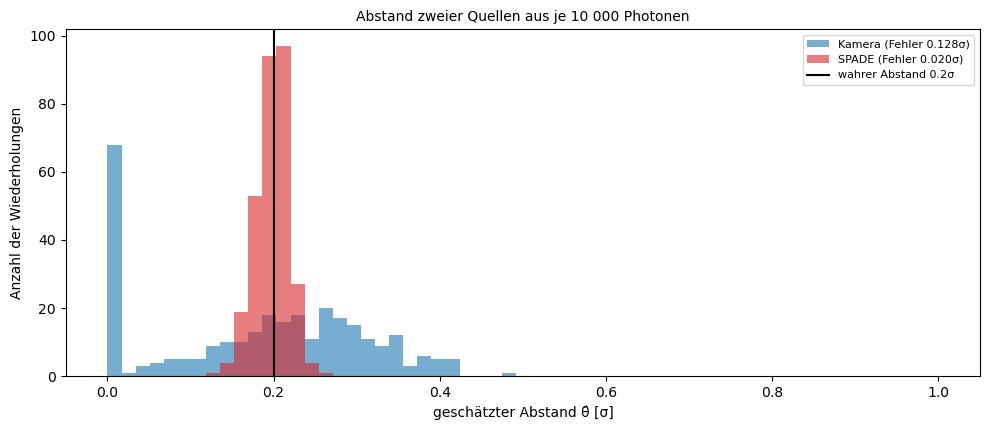

In [3]:
THETA, PHOTONS, TRIALS = 0.2, 10_000, 300        # Abstand [σ], Photonen je Messung, Wiederholungen
camera, spade = imaging.plot_estimates(THETA, PHOTONS, TRIALS)

**3. Einen Exoplaneten neben seinem Stern nachweisen**

Die schwerste Aufgabe der direkten Abbildung: Steht neben dem Stern ein schwacher Begleiter, mit dem Anteil $\varepsilon$ am Licht und im Abstand $\theta$? Das ist ein Hypothesentest, und mit $N$ Photonen fällt die Wahrscheinlichkeit, falsch zu entscheiden, wie $e^{-N D}$. Je größer der Fehlerexponent $D$ pro Photon, desto weniger Photonen braucht man. Verglichen werden Kamera und SPADE (Huang und Lupo 2021), dazu SPADE mit einem Übersprechen von 0.1 %, wie es ein echter Sortierer hat (`imaging.plot_detection`).

**Begriffe**
- **Kontrast** $\varepsilon$: Helligkeit des Planeten relativ zum Stern; bei jungen Riesenplaneten im Infrarot etwa $10^{-4}$ bis $10^{-6}$, bei einer zweiten Erde im sichtbaren Licht etwa $10^{-10}$.
- **Fehlerexponent:** Für 99.9 % Sicherheit braucht man etwa $\ln(1000)/D$ Photonen.
- **Übersprechen:** der Anteil des Sternlichts, den ein unvollkommener Sortierer in falsche Moden schickt; er täuscht einen Planeten vor.

Bei θ = 0.3σ und ε = 10⁻² braucht die Kamera 1.5·10⁶ Photonen, SPADE 3.1·10⁴, also 47-mal weniger; bei ε = 10⁻⁴ sind es 1.5·10¹⁰ gegen 3.1·10⁶, 4725-mal weniger. Der Gewinn wächst wie 1/(2ε): Der Exponent der Kamera fällt mit ε², der von SPADE nur mit ε, weil das Sternlicht in Mode 0 bleibt und die höheren Moden fast dunkel sind. Das Übersprechen nimmt einen großen Teil dieses Vorteils weg. Mit 0.1 % braucht SPADE bei ε = 10⁻⁴ schon 2.8·10⁹ Photonen, nur noch 5-mal weniger als die Kamera, und unter etwa 0.13σ ist es sogar schlechter als sie (strichpunktiert); über 3 bis 4σ trennt die Kamera Stern und Planet ohnehin. Die Quantengrenze ist erreichbar, aber nur so gut wie das Gerät.

Photonen für 99.9 % Nachweissicherheit (ln 1000 / Exponent) bei θ = 0.3σ:
  Helligkeit ε = 0.01: Kamera 1.5e+06, SPADE 3.1e+04, SPADE mit 0.001 Übersprechen 3.3e+05; Gewinn von SPADE 47-fach
  Helligkeit ε = 0.0001: Kamera 1.5e+10, SPADE 3.1e+06, SPADE mit 0.001 Übersprechen 2.8e+09; Gewinn von SPADE 4725-fach


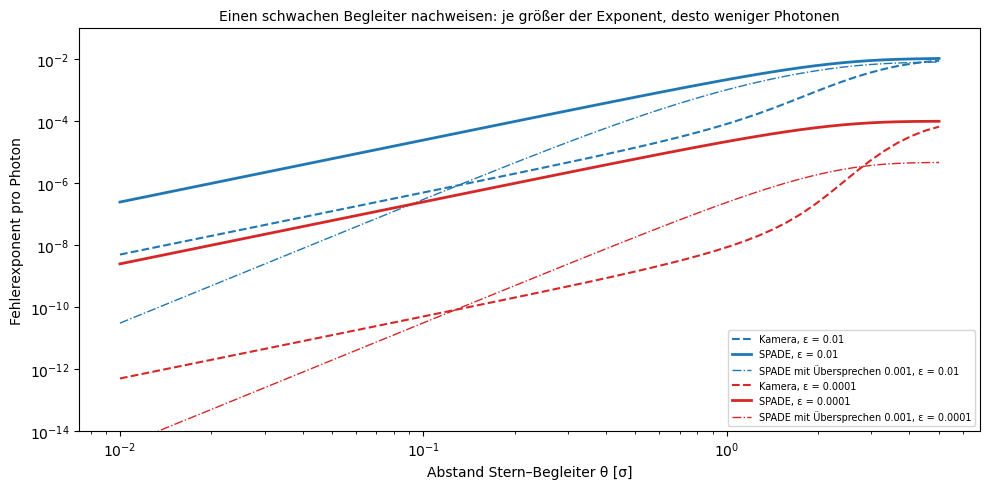

In [4]:
CONTRASTS = (1e-2, 1e-4)               # Helligkeit des Begleiters relativ zum Stern
CROSSTALK = 1e-3                        # Übersprechen des Modensortierers
imaging.plot_detection(CONTRASTS, CROSSTALK, theta_show=0.3)

**4. Wie viele bekannte Exoplaneten liegen unter der Beugungsgrenze?**

Ist das ein Randproblem? Aus dem NASA Exoplanet Archive kommen die große Halbachse $a$ und die Entfernung $d$ aller bekannten Planeten (`imaging.planets`); $a/d$ ist ihr größter Winkelabstand vom Stern, denn 1 AU in 1 pc Entfernung erscheint unter einer Bogensekunde. Verglichen wird mit $\lambda/D$ bei 1.6 µm für ein 8-m-Teleskop (VLT) und das 39-m-Teleskop ELT, das gerade gebaut wird (`imaging.plot_planets`).

**Begriffe**
- **mas:** Millibogensekunde, ein Tausendstel einer Bogensekunde.
- **Große Halbachse:** der mittlere Abstand zwischen Planet und Stern.
- **Innerer Arbeitswinkel:** der kleinste Abstand, bei dem ein Koronograph, eine Blende für das Sternlicht, noch arbeitet; etwa 3 λ/D.

Von 5 945 Planeten mit Bahn und Entfernung liegen für ein 8-m-Teleskop 93 % näher am Stern als λ/D und 96 % innerhalb des inneren Arbeitswinkels; selbst für das ELT sind es 86 % und 91 %. Der Grund ist ein Auswahleffekt: Die meisten Planeten wurden indirekt gefunden, über Transits oder die Bewegung ihres Sterns, und solche Methoden finden vor allem Planeten nah an ihrem Stern. Beispiele aus der Ausgabe: Proxima Cen b, der nächste bekannte Exoplanet, steht höchstens 37 mas von seinem Stern entfernt, knapp unter λ/D eines 8-m-Teleskops; 51 Peg b, der erste Planet um einen sonnenähnlichen Stern, nur 3.4 mas; der Riese ε Eri b mit gut einer Bogensekunde ist eine Ausnahme. Für fast alle bekannten Welten liegt die Frage also genau im Bereich der Schritte 1 bis 3.

5 945 Planeten mit Bahn und Entfernung (NASA Exoplanet Archive)
  8 m (VLT)   λ/D = 41.3 mas bei 1.6 µm: 93% der Planeten näher als λ/D, 96% näher als 3 λ/D
  39 m (ELT)  λ/D =  8.5 mas bei 1.6 µm: 86% der Planeten näher als λ/D, 91% näher als 3 λ/D


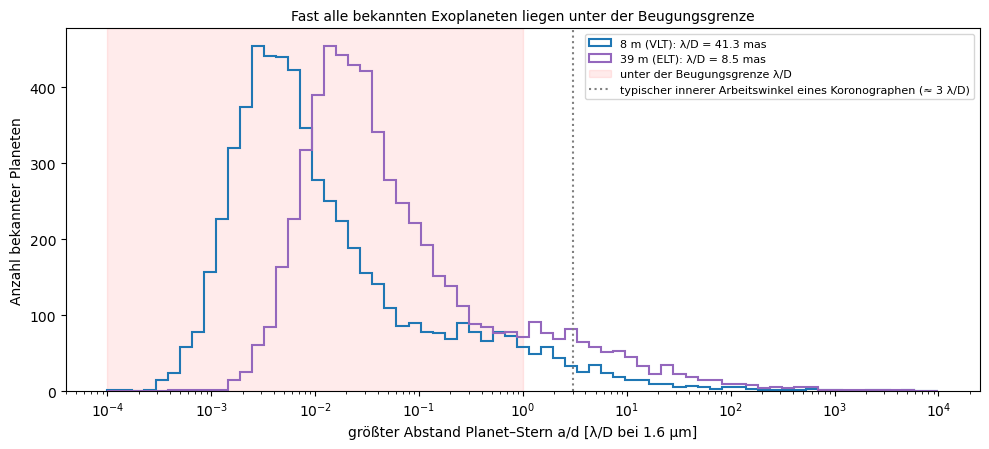

  Proxima Cen b: a = 0.0485 AU, d = 1.3 pc, größter Abstand 37.3 mas
  eps Eri b: a = 3.53 AU, d = 3.2 pc, größter Abstand 1102.2 mas
  51 Peg b: a = 0.052 AU, d = 15.5 pc, größter Abstand 3.4 mas


In [5]:
LAMBDA_UM = 1.6                                     # Wellenlänge [µm], H-Band
TELESCOPES = (("8 m (VLT)", 8.0), ("39 m (ELT)", 39.0))
known = imaging.planets(DATA)                       # beim ersten Lauf aus dem Internet, danach aus dem Cache
imaging.plot_planets(known, LAMBDA_UM, TELESCOPES)

**5. Heisenberg-Grenze: Verschränkung gegen Rauschen**

Dieselbe Frage in einem anderen Feld: Wie genau lässt sich eine Phase oder Frequenz mit $N$ Qubits messen, etwa in einer Atomuhr? $N$ unabhängige Qubits geben die Quanten-Fisher-Information $N$ und damit die Standardgrenze $\Delta\varphi = 1/\sqrt N$. Ein verschränkter GHZ-Zustand sammelt die Phase $N$-fach, erreicht $N^2$ und damit die Heisenberg-Grenze $1/N$. Mit Dephasierung, dem Verlust der Phase mit der Rate $\gamma$, zerfällt der GHZ-Zustand aber $N$-mal schneller. Verglichen werden beide bei fester Gesamtzeit und jeweils bester Messdauer (`limits.plot_metrology`); die Formeln $F = N e^{-2\gamma t}$ und $F = N^2 e^{-2N\gamma t}$ sind an Dichtematrizen für $N \le 5$ nachgerechnet.

**Begriffe**
- **GHZ-Zustand:** $(\vert 00\ldots0\rangle + \vert 11\ldots1\rangle)/\sqrt2$, alle Qubits gemeinsam in Überlagerung; die Phase wirkt auf alle zugleich.
- **Dephasierung:** zufällige Störungen, die die Phase zwischen $\vert 0\rangle$ und $\vert 1\rangle$ verwischen; die Kohärenz fällt wie $e^{-\gamma t}$.
- **Standardgrenze:** die Genauigkeit unabhängiger Teilchen, $1/\sqrt N$, beim Licht das Schrotrauschen.

Ohne Rauschen ist der GHZ-Zustand bei 100 Qubits 10-mal genauer (links). Mit Dephasierung (rechts) liefern beide bei bester Messdauer genau denselben Fehler, Verhältnis 1.00: Der GHZ-Zustand muss 100-mal kürzer messen (0.005/γ statt 0.5/γ) und verliert dabei genau, was er gewonnen hat. Mit der Messdauer des Produktzustands wird er sogar weit schlechter (gepunktet). Allgemein lässt unkorreliertes Rauschen nur einen konstanten Gewinn übrig (Escher und andere 2011, Demkowicz-Dobrzański und andere 2012). Deshalb gehen Gravitationswellen-Detektoren einen anderen Weg: LIGO speist gequetschtes Licht ein und senkt so das Schrotrauschen um bis zu 3 dB (Tse und andere 2019), ein konstanter Faktor unter der Standardgrenze.

Ohne Rauschen, N = 100 Qubits: Standardgrenze Δφ = 0.100, Heisenberg-Grenze 0.010 (10-mal genauer)
Mit Dephasierung γ, Gesamtzeit T = 1/γ, beste Messdauer: Δω Produkt 0.2332 γ, GHZ 0.2332 γ (Verhältnis 1.00); beste Messdauer GHZ 0.0050/γ statt 0.5/γ


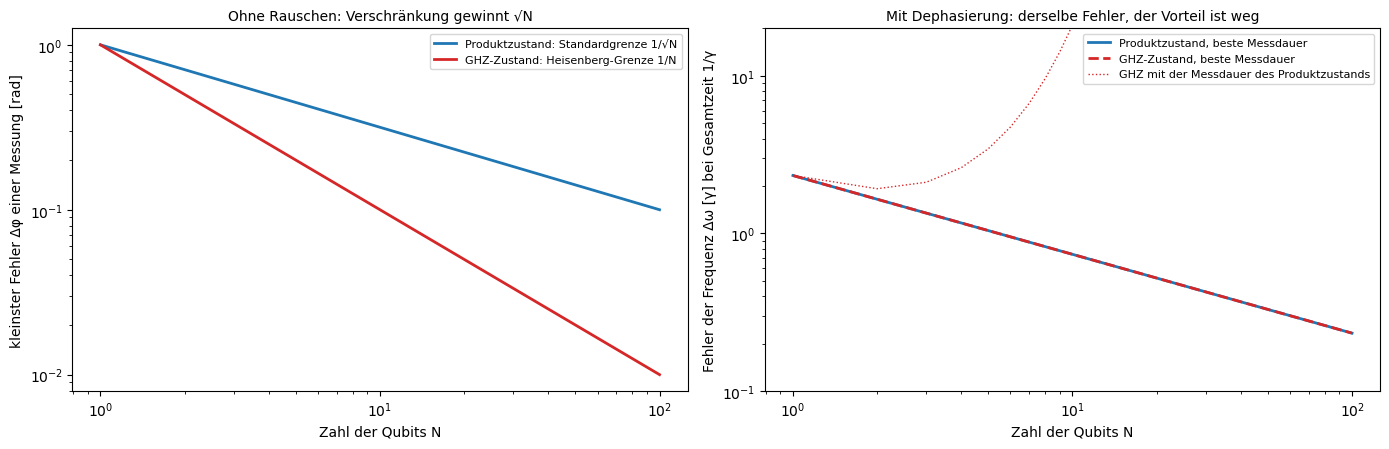

In [6]:
N_MAX, GAMMA = 100, 1.0                 # größte Zahl der Qubits, Rate der Dephasierung
limits.plot_metrology(N_MAX, GAMMA)

**6. Die Rechengrenze: Paritäten mit Rauschen**

Jetzt ein Fall, in dem die Information in den Daten steckt, aber kaum herauszuholen ist. Gesucht ist ein Geheimnis $s$ aus $n$ Bit. Jedes Beispiel besteht aus einem zufälligen Bitvektor $a$ und der Parität $a \cdot s$ (Summe modulo 2), die mit der Wahrscheinlichkeit $\eta = 1/8$ falsch ist; das ist Learning Parity with Noise (LPN). Ohne Rauschen findet das gaußsche Eliminationsverfahren $s$ aus $n$ Beispielen sofort; mit Rauschen versagt es, und das einfachste sichere Verfahren prüft alle $2^n$ Kandidaten. Gemessen wird, wie viele Beispiele diese Suche braucht und wie lange sie dauert (`limits.plot_lpn`).

**Begriffe**
- **Parität:** ob die Zahl der Stellen, an denen $a$ und $s$ beide 1 sind, gerade oder ungerade ist.
- **Binäre Entropie** $H(\eta)$: die Unsicherheit eines Münzwurfs mit Wahrscheinlichkeit $\eta$, bei $\eta = 1/8$ sind es 0.54 Bit. Ein Beispiel trägt deshalb höchstens $1 - H = 0.46$ Bit über $s$ (Kanalkapazität nach Shannon).
- **Fano-Ungleichung:** Mit $m$ Beispielen trifft kein Verfahren öfter als $(m(1-H) + 1)/n$.

Links ist die Information schnell da: Für n = 16 findet die Suche das Geheimnis ab etwa 29 Beispielen in der Hälfte der Fälle und ab etwa 50 fast immer; alle Punkte bleiben unter der Fano-Grenze (gestrichelt). Rechts wächst die Rechenzeit etwa wie 2^(1.1·n): 0.3 s für n = 20, hochgerechnet einige Wochen für n = 40 und Millionen Jahre für n = 64. Die besten bekannten Algorithmen sind schneller als diese Suche, etwa 2^(n/log n) (Blum, Kalai und Wasserman 2003), aber nicht polynomiell; genau darauf bauen Kryptoverfahren auf, die auch Quantencomputern standhalten sollen, wie LPN und Learning with Errors. Für Quantenzustände gibt es dasselbe Muster: Pseudozufällige Quantenzustände enthalten schon in wenigen Kopien genug Information, um sie zu erkennen, lassen sich aber nach heutigem Wissen nicht effizient von echt zufälligen unterscheiden (Ji, Liu und Song 2018).

Rauschen eta = 0.125: ein Beispiel trägt höchstens 1 − H(eta) = 0.456 Bit, gebraucht werden n Bit; mit m Beispielen ist die Trefferquote höchstens (m(1 − H) + 1)/n (Fano)
  n =  8: Hälfte gefunden ab etwa 11 Beispielen; sicher erst ab etwa n/(1 − H) = 18; Fano-Grenze bei 11 Beispielen 0.75
  n = 12: Hälfte gefunden ab etwa 20 Beispielen; sicher erst ab etwa n/(1 − H) = 26; Fano-Grenze bei 20 Beispielen 0.86


  n = 16: Hälfte gefunden ab etwa 29 Beispielen; sicher erst ab etwa n/(1 − H) = 35; Fano-Grenze bei 29 Beispielen 0.90


  Suche bei n = 40: etwa 6.7e+05 s = 2.1e-02 Jahre (hochgerechnet)
  Suche bei n = 64: etwa 3.0e+13 s = 9.4e+05 Jahre (hochgerechnet)
  Suche bei n = 128: etwa 7.2e+33 s = 2.3e+26 Jahre (hochgerechnet)
  gemessen: Rechenzeit wächst wie 2^(1.06·n); n = 20 braucht 0.3 s


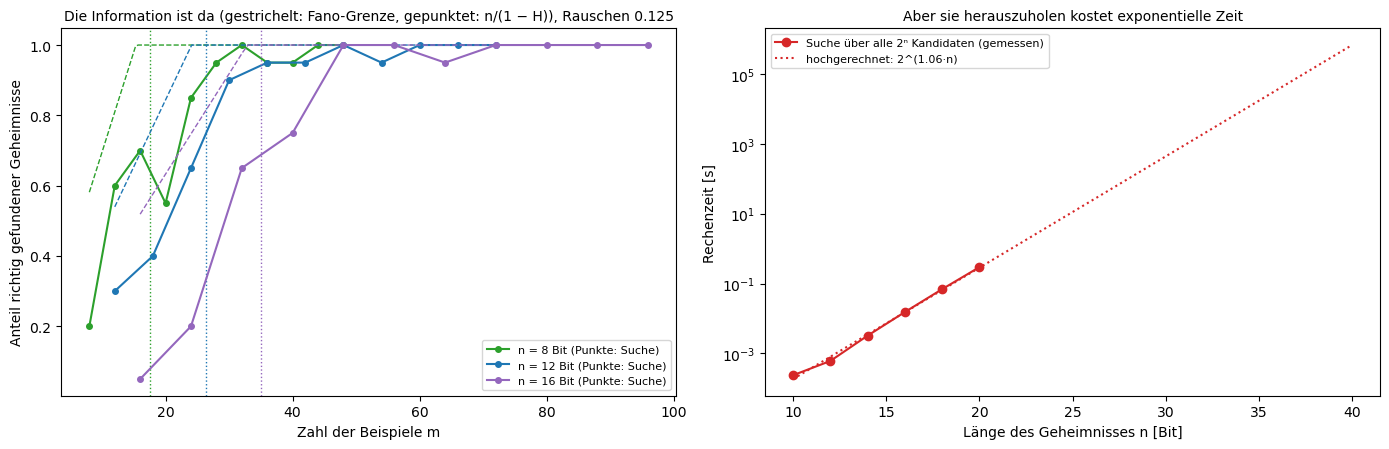

In [7]:
ETA = 0.125                             # Wahrscheinlichkeit einer falschen Parität
limits.plot_lpn(ns=(8, 12, 16), eta=ETA, trials=20, ns_time=(10, 12, 14, 16, 18, 20))

**7. Signal oder Zufall: wie viele Testaufgaben eine KI-Evaluation braucht**

Zurück zur Münze der Einführung, jetzt im Alltag der KI: Ein Agent löst jede Testaufgabe mit der Wahrscheinlichkeit $p$. Jede Aufgabe trägt die Fisher-Information $1/(p(1-p))$, mehr gibt es nicht. Wie viele Aufgaben braucht ein Vergleich zweier Agenten, damit ein Unterschied kein Zufall ist? Gerechnet wird der übliche Test zweier Anteile (Irrtum 5 %, Trennschärfe 80 %) und per Simulation geprüft (`limits.plot_evaluation`). Dazu zwei verbreitete Kennzahlen aus denselben Versuchen: pass@k, ob mindestens einer von $k$ Versuchen gelingt, und pass^k, ob alle $k$ gelingen.

**Begriffe**
- **Trennschärfe:** der Anteil der Vergleiche, die einen echten Unterschied auch finden.
- **pass@k** $= 1 - (1-p)^k$: misst, ob ein Agent etwas überhaupt kann.
- **pass^k** $= p^k$: misst, ob er es zuverlässig kann.

Bei p = 0.70 ist eine Erfolgsquote aus 100 Aufgaben nur auf ±0.046 genau, aus 1000 auf ±0.014. Um 0.70 von 0.75 zu unterscheiden, braucht man 1 251 Aufgaben je Agent, für 0.70 gegen 0.80 noch 294; die Simulation trifft die 80 % Trennschärfe genau (links). Ein Vergleich mit ein paar hundert Aufgaben kann Unterschiede von wenigen Prozentpunkten also nicht auflösen. Rechts dieselbe Erfolgsquote 0.7 in zwei Kennzahlen: pass@5 = 0.998, pass^5 = 0.168. Ein Agent, der fast immer irgendwann richtig liegt, ist noch lange nicht zuverlässig.

Ein Agent mit Erfolgsquote 0.7: Fisher-Information je Aufgabe 1/(p(1 − p)) = 4.76, also Standardfehler √(p(1 − p)/N): bei 100 Aufgaben ±0.046, bei 1000 ±0.014
  0.70 gegen 0.75: 1 251 Aufgaben je Agent für 80 % Trennschärfe (simuliert: 80%)
  0.70 gegen 0.80: 294 Aufgaben je Agent für 80 % Trennschärfe (simuliert: 80%)


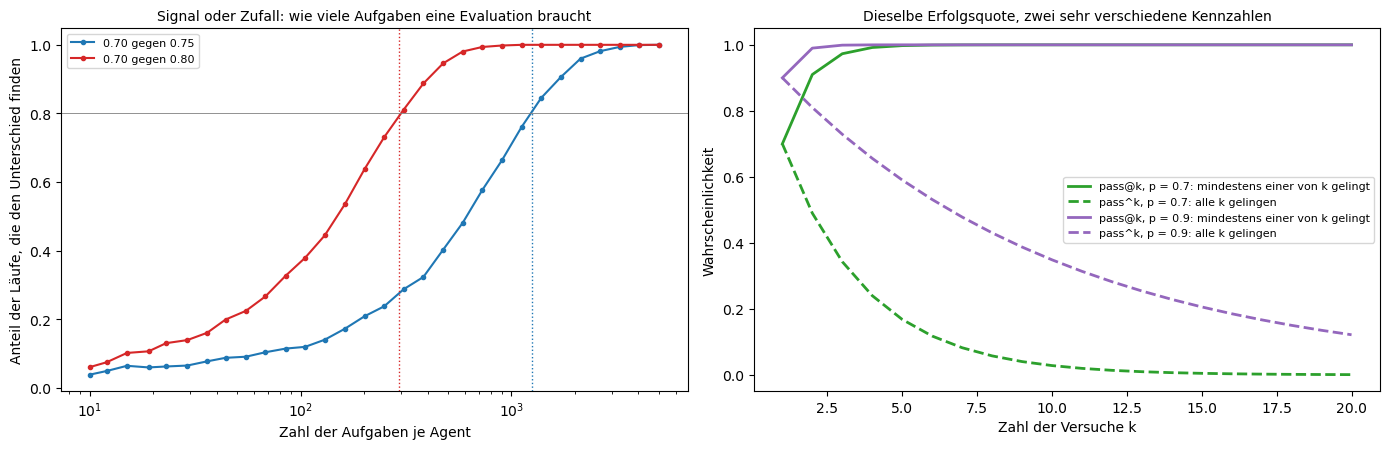

  pass@5 und pass^5 bei p = 0.7: 0.998 und 0.168; bei p = 0.9: 0.99999 und 0.590


In [8]:
P, DELTAS = 0.70, (0.05, 0.10)          # Erfolgsquote des ersten Agenten, Abstand zum zweiten
limits.plot_evaluation(P, DELTAS)